In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1

In [2]:
def bwf(filter_order,cutoff_frequency,sampling_frequency):

    analog_b,analog_a = butter(filter_order,cutoff_frequency,analog=True,btype='low') #continuous signal + low pass filter

    print(analog_b)
    print(analog_a)

    digital_b,digital_a = bilinear(analog_b,analog_a,sampling_frequency) #perform bilinear 

    return digital_b,digital_a


In [3]:
filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000

In [4]:
digital_b,digital_a = bwf(filter_order,cutoff_frequency,sampling_frequency)

[1.e+12]
[1.00000000e+00 2.61312593e+03 3.41421356e+06 2.61312593e+09
 1.00000000e+12]


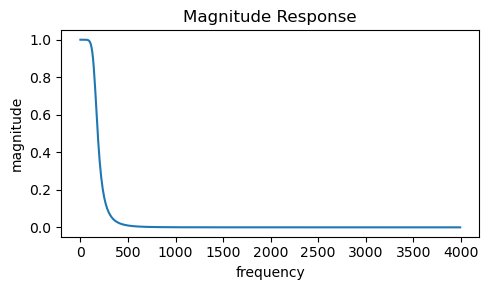

In [5]:
frequency, magnitude_response = freqz(digital_b,digital_a,fs=sampling_frequency)

plt.figure(figsize=(5,3))
plt.plot(frequency,np.abs(magnitude_response))
plt.title("Magnitude Response")
plt.xlabel("frequency")
plt.ylabel("magnitude")
plt.tight_layout()

plt.show()


c:\Users\Priya\anaconda3\Lib\site-packages\matplotlib\cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Priya\anaconda3\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


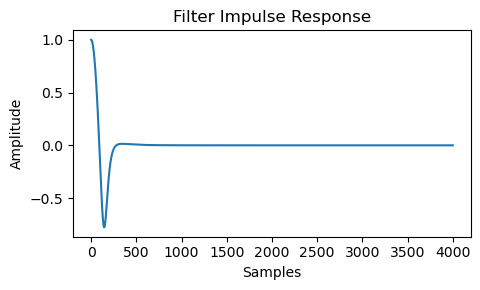

In [6]:
frequency,impulse_response = freqz(digital_b,digital_a,fs=sampling_frequency,worN=4000)

plt.figure(figsize=(5,3))
plt.plot(impulse_response)
plt.title("Filter Impulse Response")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.tight_layout()

plt.show()

In [7]:
def cf(filter_order,cutoff_frequency,sampling_frequency,ripple):

    wc = 2*sampling_frequency*np.tan(np.pi*cutoff_frequency/sampling_frequency)
    analog_b,analog_a = cheby1(filter_order,ripple,wc,analog=True,btype='low') #continuous signal + low pass filter

    print(analog_b)
    print(analog_a)

    digital_b,digital_a = bilinear(analog_b,analog_a,sampling_frequency) #perform bilinear 

    return digital_b,digital_a

In [8]:
filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000
ripple = 0.5

In [9]:
digital_b,digital_a = cf(filter_order,cutoff_frequency,sampling_frequency,ripple)

[6.90358128e+14]
[1.00000000e+00 7.93557405e+03 7.54093239e+07 2.98503630e+11
 7.31264419e+14]


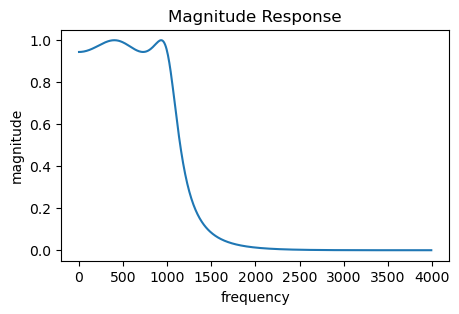

In [10]:
frequency, magnitude_response = freqz(digital_b,digital_a,fs=sampling_frequency)

plt.figure(figsize=(5,3))
plt.plot(frequency,np.abs(magnitude_response))
plt.title("Magnitude Response")
plt.xlabel("frequency")
plt.ylabel("magnitude")

plt.show()


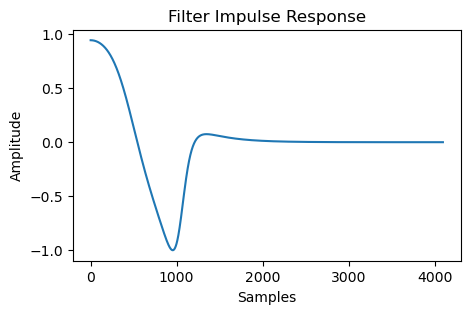

In [11]:
frequency,impulse_response = freqz(digital_b,digital_a,fs=sampling_frequency,worN=4096)

plt.figure(figsize=(5,3))
plt.plot(impulse_response)
plt.title("Filter Impulse Response")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.show()

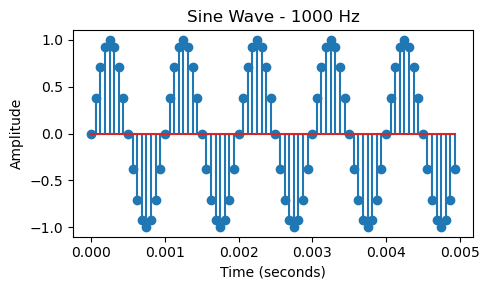

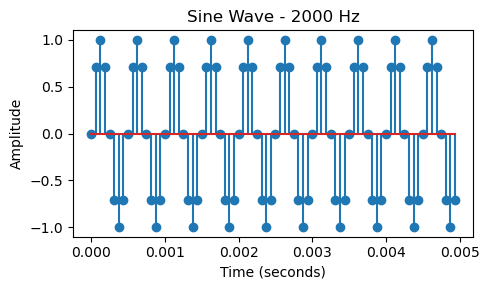

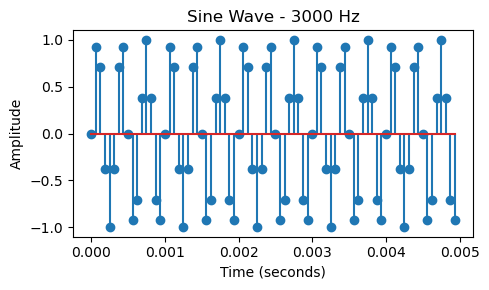

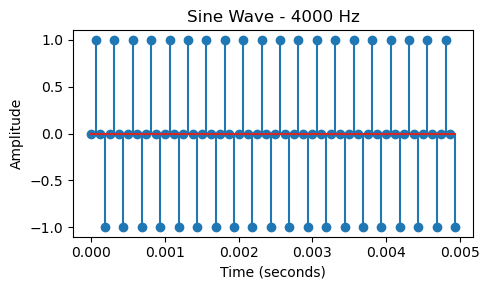

In [ ]:
#TASK1 - Generate a discrete sine wave of 1 KHz,2KHz, 3 KHz, 4 KHz. Plot all these

sampling_frequency = 16000
t = np.arange(0, 1, 1/sampling_frequency)

x1 = np.sin(2*np.pi*1000*t)
x2 = np.sin(2*np.pi*2000*t)
x3 = np.sin(2*np.pi*3000*t)
x4 = np.sin(2*np.pi*4000*t)

signals = [x1, x2, x3, x4]
frequencies = [1000, 2000, 3000, 4000]

for i in range(4):
    plt.figure(figsize=(5, 3))
    samples = int(0.005 * sampling_frequency)
    plt.stem(t[:samples], signals[i][:samples])
    plt.title(f"Sine Wave - {frequencies[i]} Hz")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.tight_layout()
    plt.show()


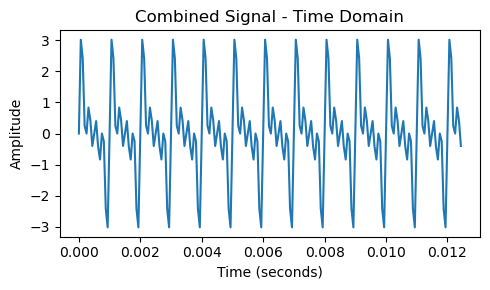

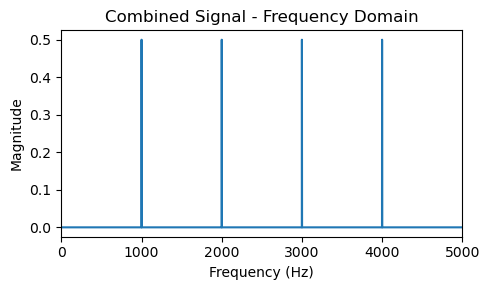

In [14]:

#TASK2 - Add all these four signal and plot it in time as well as frequency domain

combined_signal = x1 + x2 + x3 + x4

# Time domain
plt.figure(figsize=(5, 3))
plt.plot(t[:200], combined_signal[:200])
plt.title("Combined Signal - Time Domain")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

# Frequency domain
N = len(combined_signal)
frequency = np.fft.rfftfreq(N, 1/sampling_frequency)
magnitude = np.abs(np.fft.rfft(combined_signal))/N

plt.figure(figsize=(5, 3))
plt.plot(frequency, magnitude)
plt.title("Combined Signal - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 5000)
plt.tight_layout()
plt.show()


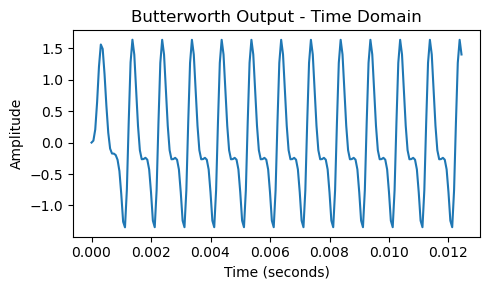

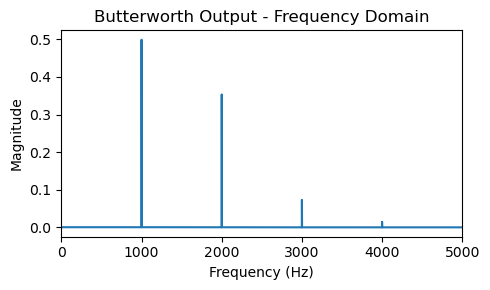

In [ ]:
#TASK3 - Pass through butterworth digital filter having cutff frequency 2 KHz Andplot the output plot in time as well as frequency domain


filter_order = 4
cutoff_frequency = 2000

digital_b, digital_a = bwf(
    filter_order, cutoff_frequency, sampling_frequency
)

butterworth_output = np.zeros_like(combined_signal)

# Apply the filter using the difference equation
from scipy.signal import lfilter
butterworth_output = lfilter(
    digital_b, digital_a, combined_signal
)

# Time domain
plt.figure(figsize=(5, 3))
plt.plot(t[:200], butterworth_output[:200])
plt.title("Butterworth Output - Time Domain")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

# Frequency domain
frequency = np.fft.rfftfreq(N, 1/sampling_frequency)
magnitude = np.abs(np.fft.rfft(butterworth_output))/N

plt.figure(figsize=(5, 3))
plt.plot(frequency, magnitude)
plt.title("Butterworth Output - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 5000)
plt.tight_layout()
plt.show()


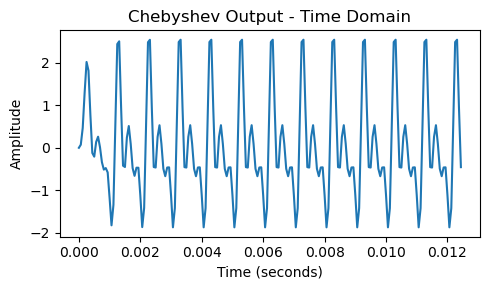

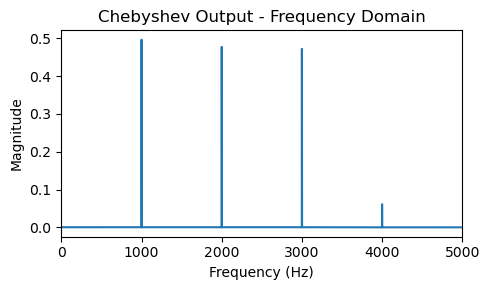

In [16]:
#TASK-4 : Pass through chebyschev digital filter having cutoff frequency 3 KHz and plot the output plot in time as well as frequency domain


filter_order = 4
cutoff_frequency = 3000
ripple = 0.5

digital_b, digital_a = cf(
    filter_order, cutoff_frequency,
    sampling_frequency, ripple
)

chebyshev_output = lfilter(
    digital_b, digital_a, combined_signal
)

# Time domain
plt.figure(figsize=(5, 3))
plt.plot(t[:200], chebyshev_output[:200])
plt.title("Chebyshev Output - Time Domain")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

# Frequency domain
frequency = np.fft.rfftfreq(N, 1/sampling_frequency)
magnitude = np.abs(np.fft.rfft(chebyshev_output))/N

plt.figure(figsize=(5, 3))
plt.plot(frequency, magnitude)
plt.title("Chebyshev Output - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 5000)
plt.tight_layout()
plt.show()
